# Why the PS-08 Dataset Cannot Support the Stated Task

**Every claim in `WHY_SIH_DATA_FAILS.md`, recomputed from the delivered files.**

Problem statement PS-08 asks for a model that learns the time-varying build-up of
broadcast ephemeris and clock error from **seven days of data for one satellite**,
and predicts the eighth day at arbitrary timestamps.

This notebook tests whether the delivered dataset can support that. Each section
is one claim from the document, with the table or figure behind it.

The findings fall into three classes:

| Part | Claim | Fixable? |
|---|---|---|
| **I** | The files as delivered are defective | in principle, by re-issuing them |
| **II** | The GEO file is not a physical time series at all | in principle, by re-issuing them |
| **III** | Even a *perfect* seven-day file is structurally insufficient | **by no one** — it is a property of the observation window |

Part III is the important one.

**Two data sources are used:**

- `Data_PS-08/` — the six delivered CSVs
- `../full2.parquet` — our 244-day reference corpus (2,067,234 epochs, 103 spacecraft,
  CDDIS `BRDM00DLR` broadcast nav differenced against `JAX0MGXFIN` final precise orbits,
  uniform 900 s grid). Used as the **control**: the same tests, run on real data.

Sections that need the corpus are marked **[corpus]**.

## Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats

DATA   = Path("Data_PS-08")
CORPUS = Path("../full2.parquet")
CL     = 0.299792458          # metres per nanosecond, for dClk_ns -> m

CH     = ["x", "y", "z", "clk"]
CHLAB  = {"x": "x_error", "y": "y_error", "z": "z_error", "clk": "satclockerror"}
CHCOL  = {"x": "#1f77b4", "y": "#d62728", "z": "#2ca02c", "clk": "#9467bd"}

TRAIN  = ["DATA_GEO_Train", "DATA_MEO_Train", "DATA_MEO_Train2"]
TEST   = ["DATA_GEO_Test",  "DATA_MEO_Test",  "DATA_MEO_Test2"]
FILES  = TRAIN + TEST

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "figure.titlesize": 11,
})

def load(name, dedup=True):
    # Column headers vary in whitespace between files, so replace them positionally.
    # Returns rows sorted by time, duplicates dropped by default.
    df = pd.read_csv(DATA / f"{name}.csv")
    df.columns = ["utc_time", "x", "y", "z", "clk"]
    df["t"] = pd.to_datetime(df["utc_time"], format="%m/%d/%Y %H:%M")
    if dedup:
        df = df.drop_duplicates(subset=["utc_time", "x", "y", "z", "clk"])
    return df.sort_values("t").reset_index(drop=True)

def show(df, caption=None):
    if caption:
        print(caption)
    display(df)

RAW = {n: load(n, dedup=False) for n in FILES}
SIH = {n: load(n, dedup=True)  for n in FILES}

print(f"{'file':20s} {'rows':>6s} {'unique':>7s} {'span (d)':>9s}")
for n in FILES:
    s = SIH[n]
    print(f"{n:20s} {len(RAW[n]):6d} {len(s):7d} "
          f"{(s.t.max()-s.t.min()).total_seconds()/86400:9.2f}")

file                   rows  unique  span (d)
DATA_GEO_Train          142     142      6.74
DATA_MEO_Train           90      46      6.08
DATA_MEO_Train2         244     143      6.06
DATA_GEO_Test            69      69      0.98
DATA_MEO_Test            11       6      0.21
DATA_MEO_Test2           30      18      0.23


---

# Part 0 — The data as it arrives

Before any test: what do the delivered series actually look like?

Each channel is **z-scored within its own file** (subtract mean, divide by sd) so
that four quantities of very different magnitude — position error in metres and
clock error in metres — can share an axis. Normalisation hides scale and shows
*shape*, which is what these plots are for.

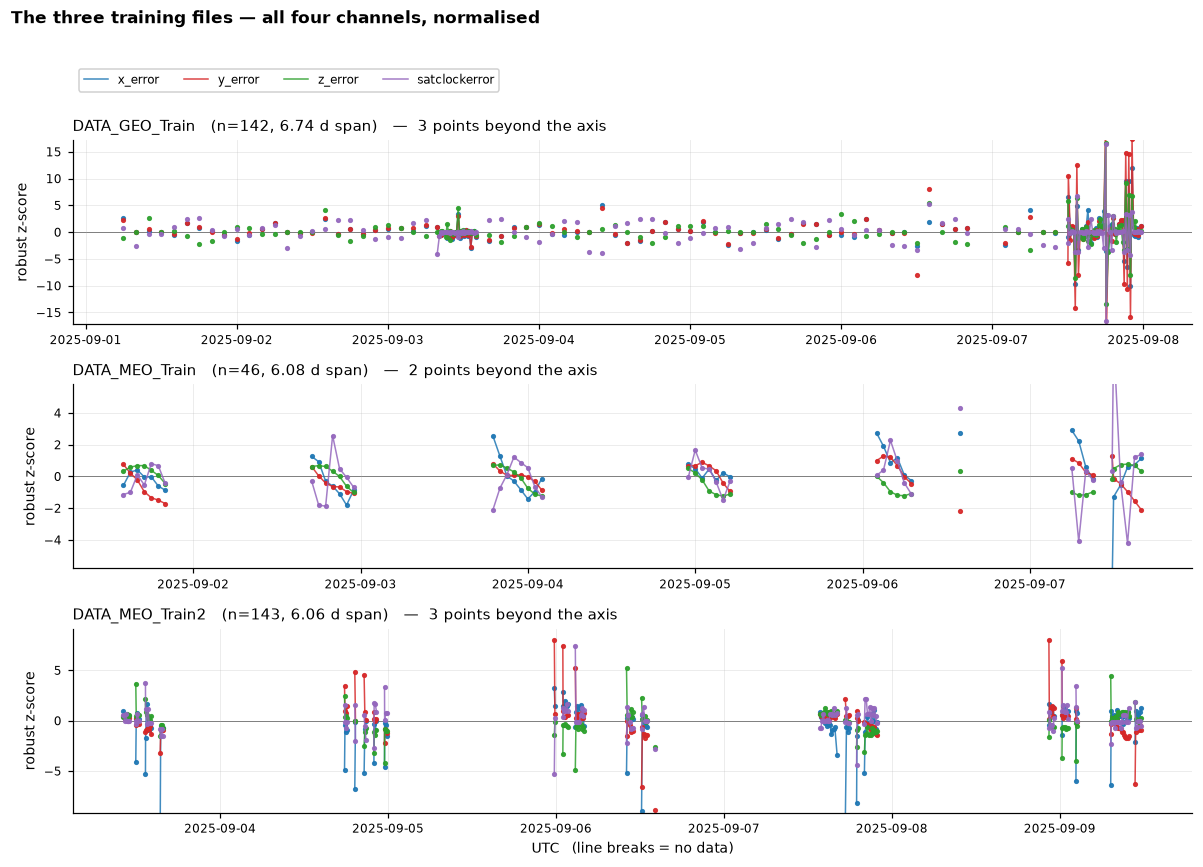

In [2]:
def zscore(v):
    # Robust scaling (median / MAD). A plain mean/sd z-score is dominated by the
    # single violent day at the end of GEO_Train and flattens the other six.
    v = np.asarray(v, float)
    med = np.median(v)
    mad = np.median(np.abs(v - med))
    s = 1.4826*mad if mad > 0 else v.std()
    return (v - med)/s if s > 0 else v - med

def break_gaps(t, v, maxgap):
    # Insert NaN across sampling gaps so the line is not drawn through them.
    # Without this, a 21-hour hole is rendered as a straight line of "data".
    tv = t.values.astype("datetime64[ns]")
    vv = np.asarray(v, float)
    dt = np.diff(tv).astype("timedelta64[s]").astype(float)
    idx = np.where(dt > maxgap)[0] + 1
    return np.insert(tv, idx, tv[idx-1]), np.insert(vv, idx, np.nan)

def series_panel(names, title):
    fig, axes = plt.subplots(len(names), 1, figsize=(11, 2.6*len(names)))
    axes = np.atleast_1d(axes)
    for ax, n in zip(axes, names):
        d = SIH[n]
        dt = np.diff(d.t.values).astype("timedelta64[s]").astype(float)
        maxgap = max(2*np.median(dt), 1800)
        for c in CH:
            z = zscore(d[c])
            tg, zg = break_gaps(d.t, z, maxgap)
            ax.plot(tg, zg, lw=1.0, color=CHCOL[c], alpha=0.85, label=CHLAB[c])
            ax.plot(d.t, z, ls="none", marker="o", ms=2.4, color=CHCOL[c], alpha=0.9)
        ax.axhline(0, color="0.4", lw=0.6, zorder=0)
        # Clip the axis to the bulk. GEO_Train's last day is ~30x the variance of
        # the rest (section 5), and on a full-range axis it flattens the other six
        # days into a straight line and hides the sample-to-sample structure.
        allz = np.concatenate([zscore(d[c]) for c in CH])
        lim = np.percentile(np.abs(allz), 98)*1.4
        ax.set_ylim(-lim, lim)
        off = int((np.abs(allz) > lim).sum())
        ax.set_title(f"{n}   (n={len(d)}, "
                     f"{(d.t.max()-d.t.min()).total_seconds()/86400:.2f} d span)"
                     + (f"   —  {off} points beyond the axis" if off else ""),
                     loc="left")
        ax.set_ylabel("robust z-score")
    axes[0].legend(ncol=4, loc="upper left", framealpha=0.9,
                   bbox_to_anchor=(0, 1.42))
    axes[-1].set_xlabel("UTC   (line breaks = no data)")
    fig.suptitle(title, y=1.005, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    plt.show()

series_panel(TRAIN, "The three training files — all four channels, normalised")

Read these three panels against each other:

- **`DATA_GEO_Train`** sits near zero for six days and then erupts — the last day
  carries roughly 30× the variance of the first (§5). At six days' width its
  sample-to-sample behaviour cannot be resolved; §7 zooms in on five hours of
  `DATA_GEO_Test`, and that is where the artefact becomes visible.
- **`DATA_MEO_Train`** is smooth *within* each run, and the runs are separated by
  21-hour holes. The line is broken across every gap, so the white space is missing
  data rather than a flat signal.
- **`DATA_MEO_Train2`** is denser, in six clusters, with large excursions at the
  start of each — those turn out to be exactly the stale-ephemeris spikes of §10.

Both MEO files show the same thing: what looks like a week is six or seven short
sessions. Nothing in between was measured.

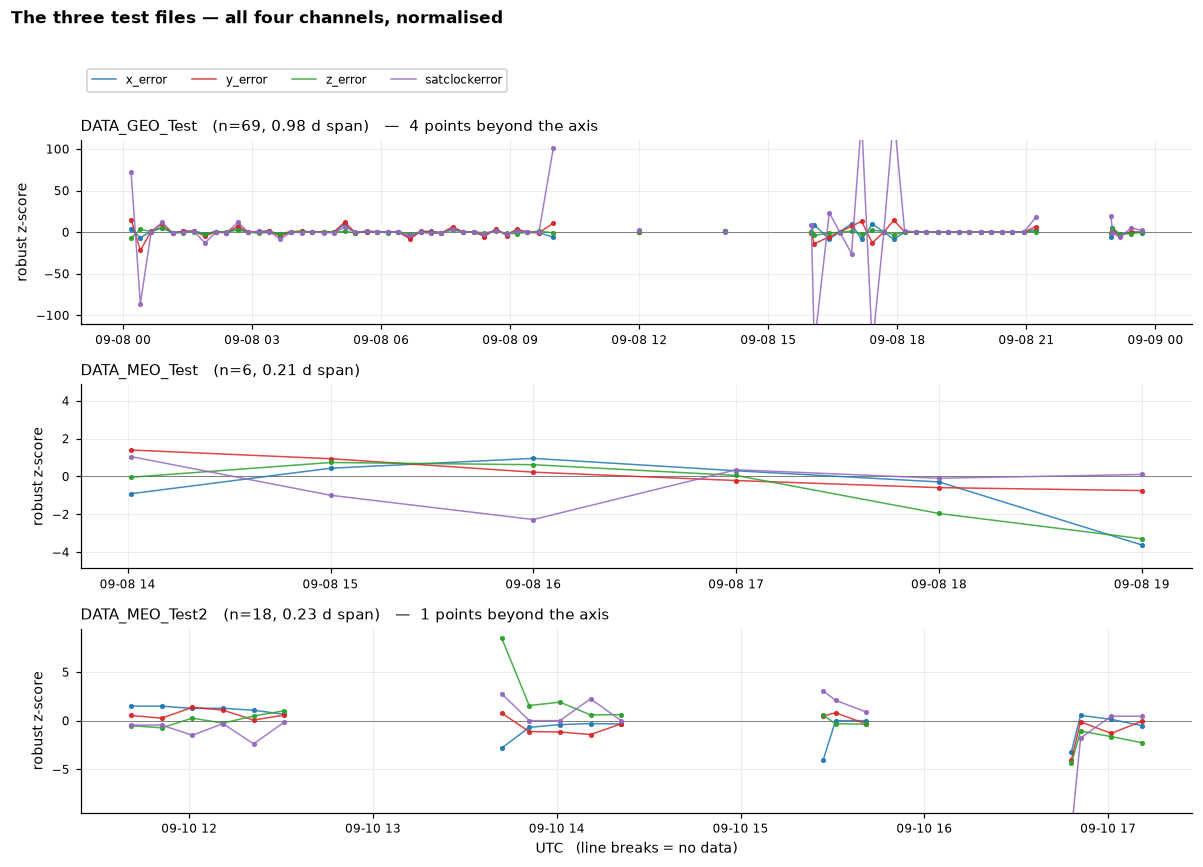

In [3]:
series_panel(TEST, "The three test files — all four channels, normalised")

`DATA_MEO_Test` is **six points**. `DATA_MEO_Test2` is eighteen. `DATA_GEO_Test` is
the most serrated series in the whole delivery.

---

# Part I — The files as delivered

## §1 — Every MEO file is roughly half duplicated rows

Each row appears twice, byte-identical across all four channels. These are not two
satellites sharing a timestamp — they are the same record repeated.

,rows,unique,duplicated,wasted %
file,,,,
DATA_GEO_Train,142,142,0,0.0
DATA_MEO_Train,90,46,44,48.9
DATA_MEO_Train2,244,143,101,41.4
DATA_GEO_Test,69,69,0,0.0
DATA_MEO_Test,11,6,5,45.5
DATA_MEO_Test2,30,18,12,40.0


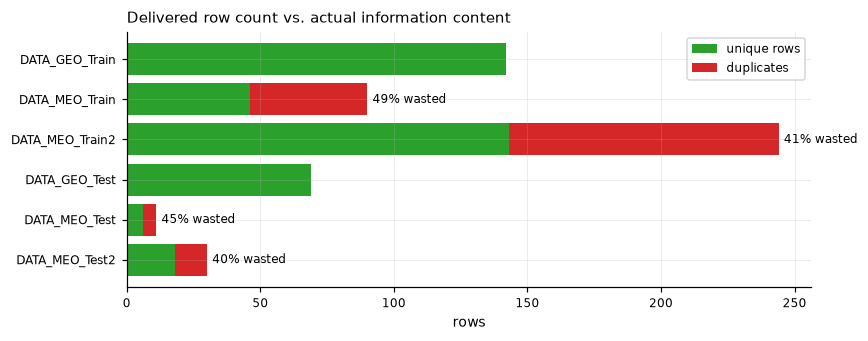

In [4]:
rows = []
for n in FILES:
    r, u = len(RAW[n]), len(SIH[n])
    rows.append({"file": n, "rows": r, "unique": u,
                 "duplicated": r - u, "wasted %": 100*(1 - u/r)})
t1 = pd.DataFrame(rows).set_index("file")
show(t1.round(1))

fig, ax = plt.subplots(figsize=(8, 3.2))
y = np.arange(len(t1))
ax.barh(y, t1["unique"], color="#2ca02c", label="unique rows")
ax.barh(y, t1["duplicated"], left=t1["unique"], color="#d62728", label="duplicates")
ax.set_yticks(y); ax.set_yticklabels(t1.index); ax.invert_yaxis()
ax.set_xlabel("rows"); ax.legend()
ax.set_title("Delivered row count vs. actual information content", loc="left")
for i, (u, d) in enumerate(zip(t1["unique"], t1["duplicated"])):
    if d: ax.text(u+d+2, i, f"{100*d/(u+d):.0f}% wasted", va="center", fontsize=8)
fig.tight_layout(); plt.show()

> **`DATA_MEO_Test.csv` contains six data points.** Any metric computed on it —
> Shapiro-Wilk included — is dominated by sampling noise.

## §2 — No file actually spans seven days

"Seven-day training data" is not what was delivered. Coverage below is the union of
±15 min windows around each retained sample, as a fraction of 168 hours.

In [5]:
def coverage(ts, half=900):
    iv = sorted((x-half, x+half) for x in ts)
    merged = []
    for a, b in iv:
        if merged and a <= merged[-1][1]:
            merged[-1] = (merged[-1][0], max(merged[-1][1], b))
        else:
            merged.append((a, b))
    return sum(b-a for a, b in merged)

rows = []
for n in FILES:
    ts = SIH[n].t.values.astype("datetime64[s]").astype(float)
    dt = np.diff(ts); cov = coverage(ts)/3600
    rows.append({"file": n, "span (d)": (ts[-1]-ts[0])/86400,
                 "gaps > 1 h": int((dt > 3600).sum()),
                 "largest gap (h)": dt.max()/3600,
                 "hours covered": cov, "% of 7 days": 100*cov/168})
t2 = pd.DataFrame(rows).set_index("file")
show(t2.round(2))

,span (d),gaps > 1 h,largest gap (h),hours covered,% of 7 days
file,,,,,
DATA_GEO_Train,6.74,70,6.00,53.35,31.76
DATA_MEO_Train,6.08,7,21.00,22.72,13.52
DATA_MEO_Train2,6.06,19,25.93,30.00,17.86
DATA_GEO_Test,0.98,4,2.00,18.25,10.86
DATA_MEO_Test,0.21,0,1.00,3.00,1.79
DATA_MEO_Test2,0.23,3,1.18,4.10,2.44


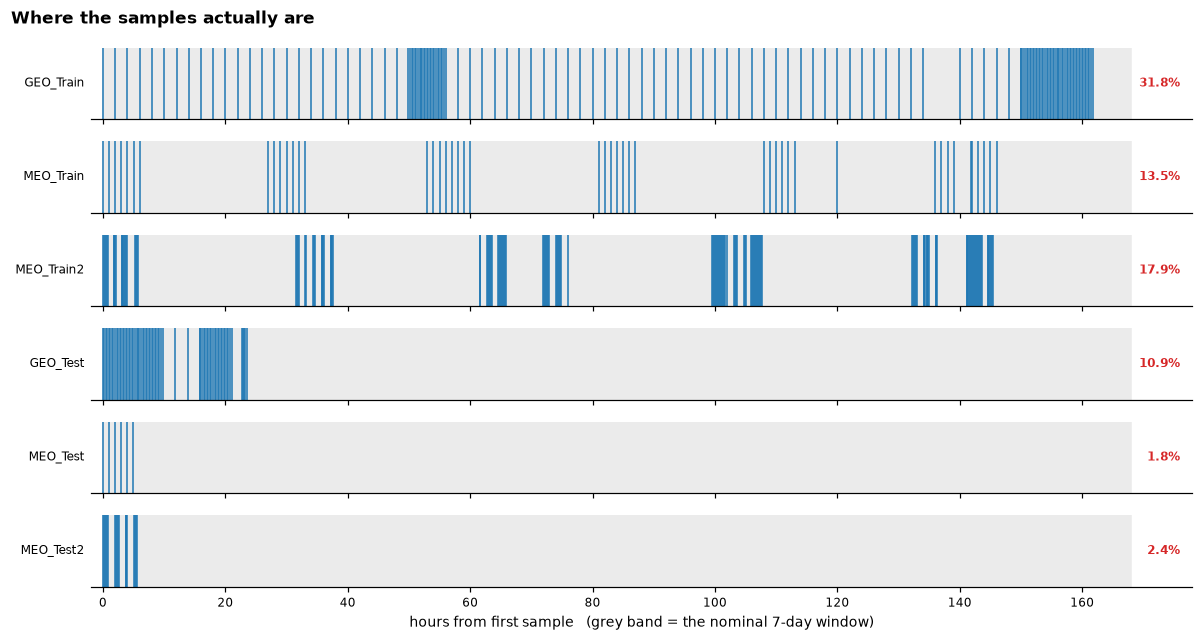

In [6]:
fig, axes = plt.subplots(len(FILES), 1, figsize=(11, 0.75*len(FILES)+1.4),
                         sharex=True)
for ax, n in zip(axes, FILES):
    d = SIH[n]
    h = (d.t - d.t.iloc[0]).dt.total_seconds().values/3600
    ax.axvspan(0, 168, color="0.92", zorder=0)
    ax.vlines(h, 0, 1, lw=1.0, color="#1f77b4")
    ax.set_xlim(-2, 178); ax.set_ylim(0, 1)
    ax.set_yticks([]); ax.grid(False)
    for sp in ("left", "right", "top"):
        ax.spines[sp].set_visible(False)
    ax.set_ylabel(n.replace("DATA_", ""), rotation=0, ha="right",
                  va="center", fontsize=8)
    ax.text(176, 0.5, f"{t2.loc[n,'% of 7 days']:.1f}%", va="center", ha="right",
            fontsize=8, color="#d62728", fontweight="bold")
axes[-1].set_xlabel("hours from first sample   (grey band = the nominal 7-day window)")
fig.suptitle("Where the samples actually are", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()

`MEO_Train` is seven runs of about seven hours each, separated by 21-hour holes.
**Over 86% of the "training week" is simply absent.** The "eighth day" in `MEO_Test`
is five hours of one afternoon.

## §3 — Effective sample size is between 1 and 5

Raw row counts overstate the information content, because consecutive samples are
correlated. With `n_eff = n·(1−ρ)/(1+ρ)`, where ρ is the lag-1 autocorrelation
measured **only on pairs actually one cadence step apart** (the files are irregular,
so pairs separated by a multi-hour gap are not lag-1 anything).

n_eff per channel


,n,cadence,pairs,x,y,z,clk
file,,,,,,,
DATA_MEO_Train,46,60 min,37,5.2,1.2,1.3,44.6
DATA_MEO_Train2,143,10 min,96,65.3,11.4,7.0,43.3


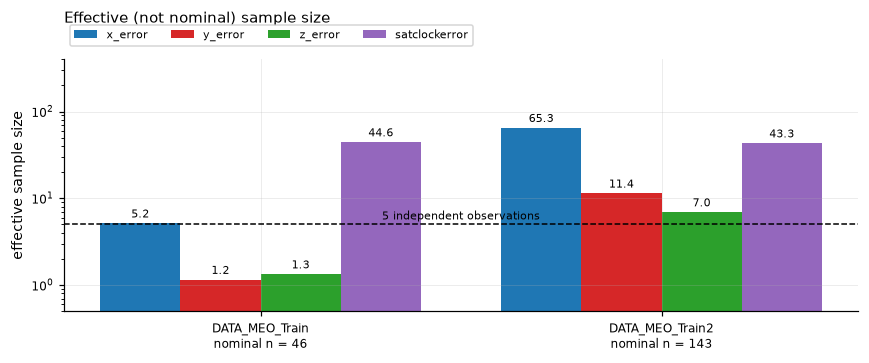

In [7]:
CADENCE = {"DATA_MEO_Train": 3600, "DATA_MEO_Train2": 600,
           "DATA_GEO_Train": 900,  "DATA_GEO_Test": 900,
           "DATA_MEO_Test": 3600,  "DATA_MEO_Test2": 600}

def neff_row(n):
    d = SIH[n]; cad = CADENCE[n]
    ts = d.t.values.astype("datetime64[s]").astype(float)
    m = np.isclose(np.diff(ts), cad)
    out = {"file": n, "n": len(d), "cadence": f"{cad//60} min", "pairs": int(m.sum())}
    for c in CH:
        v = d[c].values
        if m.sum() < 3:
            out[c] = np.nan; continue
        rho = np.corrcoef(v[:-1][m], v[1:][m])[0, 1]
        out[c] = len(v)*(1-rho)/(1+rho)
    return out

t3 = pd.DataFrame([neff_row(n) for n in ["DATA_MEO_Train", "DATA_MEO_Train2"]]).set_index("file")
show(t3.round(1), "n_eff per channel")

fig, ax = plt.subplots(figsize=(8, 3.4))
w, xs = 0.2, np.arange(len(t3))
for i, c in enumerate(CH):
    b = ax.bar(xs + (i-1.5)*w, t3[c], w, color=CHCOL[c], label=CHLAB[c])
    ax.bar_label(b, fmt="%.1f", fontsize=7, padding=2)
ax.axhline(5, color="black", ls="--", lw=1)
ax.text(0.5, 5.7, "5 independent observations", fontsize=7.5,
        color="black", ha="center")
ax.set_xticks(xs)
ax.set_xticklabels([f"{n}\nnominal n = {t3.loc[n,'n']}" for n in t3.index])
ax.set_ylabel("effective sample size"); ax.set_yscale("log")
ax.set_ylim(0.5, 400)
ax.legend(ncol=4, fontsize=7.5, loc="upper left", bbox_to_anchor=(0, 1.16))
ax.set_title("Effective (not nominal) sample size", loc="left", pad=24)
fig.tight_layout(); plt.show()

`DATA_MEO_Train.csv` carries between **one and five independent observations** of the
along-track and cross-track error. The clock column looks better only because it is
uncorrelated — §15 shows that is a defect, not a feature.

*Note: `WHY_SIH_DATA_FAILS.md` reports 70.6 / 40.8 / 30.9 / 100.8 for `MEO_Train2`,
computed with a looser pair tolerance (≤ 900 s rather than exactly 600 s). The
stricter rule used here gives smaller numbers, i.e. it is the more damning of the two.
The `MEO_Train` row — the one the claim rests on — reproduces exactly.*

## §4 — The test day is not drawn from the training distribution

The premise of the task is that day 8 continues the process observed on days 1–7.
For the GEO pair, it does not.

,train std,test std,variance ratio,Levene p
channel,,,,
x_error,5.040,13.930,7.64,0.000
y_error,8.703,19.761,5.16,0.000
z_error,6.587,10.495,2.54,0.002
satclockerror,3.809,15.896,17.42,0.003


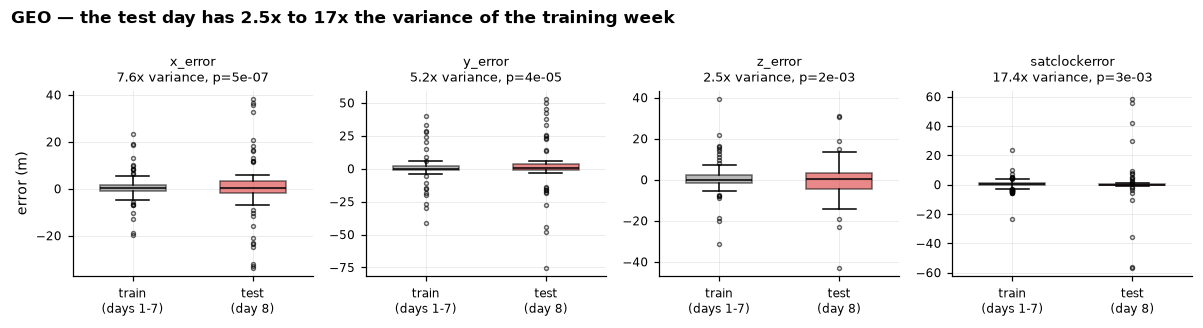

In [8]:
tr, te = SIH["DATA_GEO_Train"], SIH["DATA_GEO_Test"]
rows = []
for c in CH:
    rows.append({"channel": CHLAB[c], "train std": tr[c].std(), "test std": te[c].std(),
                 "variance ratio": te[c].var()/tr[c].var(),
                 "Levene p": stats.levene(tr[c], te[c])[1]})
t4 = pd.DataFrame(rows).set_index("channel")
show(t4.assign(**{"variance ratio": t4["variance ratio"].round(2)}).round(3))

fig, axes = plt.subplots(1, 4, figsize=(11, 3.0))
for ax, c in zip(axes, CH):
    bp = ax.boxplot([tr[c], te[c]], tick_labels=["train\n(days 1-7)", "test\n(day 8)"],
                    widths=0.55, patch_artist=True, showfliers=True,
                    flierprops=dict(ms=2.5, alpha=0.6))
    for p, col in zip(bp["boxes"], ["#7f7f7f", "#d62728"]):
        p.set_facecolor(col); p.set_alpha(0.55)
    for k in ("medians",):
        for ln in bp[k]: ln.set_color("black")
    ax.set_title(f"{CHLAB[c]}\n{t4.loc[CHLAB[c],'variance ratio']:.1f}x variance, "
                 f"p={t4.loc[CHLAB[c],'Levene p']:.0e}", fontsize=8.5)
    ax.set_ylabel("error (m)" if c == "x" else "")
fig.suptitle("GEO — the test day has 2.5x to 17x the variance of the training week",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()

A model fitted on the training week is scored against a day whose error variance is
**2.5× to 17× larger, at p < 0.003 on every channel.** This is not a hard prediction
problem; it is an ill-posed one.

## §5 — The training week is not even stationary within itself

Splitting `GEO_Train` at its midpoint.

,1st half std,2nd half std,ratio,Levene p
channel,,,,
x_error,2.435,6.717,7.609,0.000
y_error,2.209,12.151,30.266,0.000
z_error,2.713,8.939,10.859,0.000
satclockerror,2.127,4.970,5.457,0.024


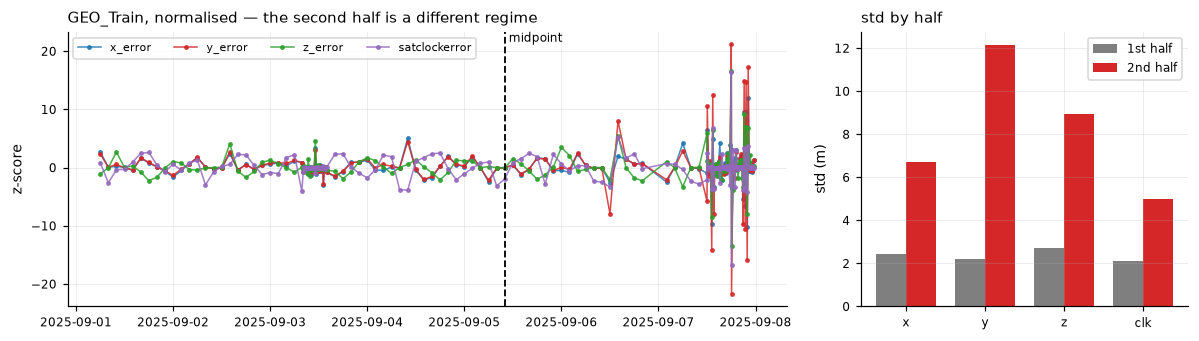

In [9]:
h = len(tr)//2
rows = []
for c in CH:
    a, b = tr[c][:h], tr[c][h:]
    rows.append({"channel": CHLAB[c], "1st half std": a.std(), "2nd half std": b.std(),
                 "ratio": b.var()/a.var(), "Levene p": stats.levene(a, b)[1]})
t5 = pd.DataFrame(rows).set_index("channel")
show(t5.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2),
                         gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
for c in CH:
    ax.plot(tr.t, zscore(tr[c]), lw=1.0, marker="o", ms=2.2,
            color=CHCOL[c], label=CHLAB[c], alpha=0.85)
ax.axvline(tr.t.iloc[h], color="black", ls="--", lw=1.2)
ax.text(tr.t.iloc[h], ax.get_ylim()[1], " midpoint", va="top", fontsize=8)
ax.set_title("GEO_Train, normalised — the second half is a different regime", loc="left")
ax.set_ylabel("z-score"); ax.legend(ncol=4, fontsize=7.5)

ax = axes[1]
w, xs = 0.38, np.arange(len(CH))
ax.bar(xs-w/2, t5["1st half std"], w, color="#7f7f7f", label="1st half")
ax.bar(xs+w/2, t5["2nd half std"], w, color="#d62728", label="2nd half")
ax.set_xticks(xs); ax.set_xticklabels(CH); ax.set_ylabel("std (m)")
ax.legend(); ax.set_title("std by half", loc="left")
fig.tight_layout(); plt.show()

**There is no single regime to learn.** The "seven days" contain at least two
statistically distinct populations, and no label distinguishes them.

## §6 — No satellite identifier  **[corpus]**

The files carry `utc_time, x_error, y_error, z_error, satclockerror` and nothing else.
No PRN, no constellation, no orbit slot. This matters because the error physics is
satellite-specific — so we measure that spread in the corpus, where satellites *are*
labelled.

Delivered columns: ['utc_time', 'x_error (m)', 'y_error (m)', 'z_error (m)', 'satclockerror (m)']


corpus: 2,067,234 epochs, 100 spacecraft, 2026-01-01 -> 2026-09-01


Per-constellation, MEO only


,sats,median |clock| (m),median |pos| (m)
BeiDou,30,0.148,0.293
Galileo,26,0.092,0.246
GPS,32,0.078,0.801



per-satellite |clock| spans 0.053 to 0.232 m (4.4x)
per-satellite |pos|   spans 0.204 to 1.054 m (5.2x)


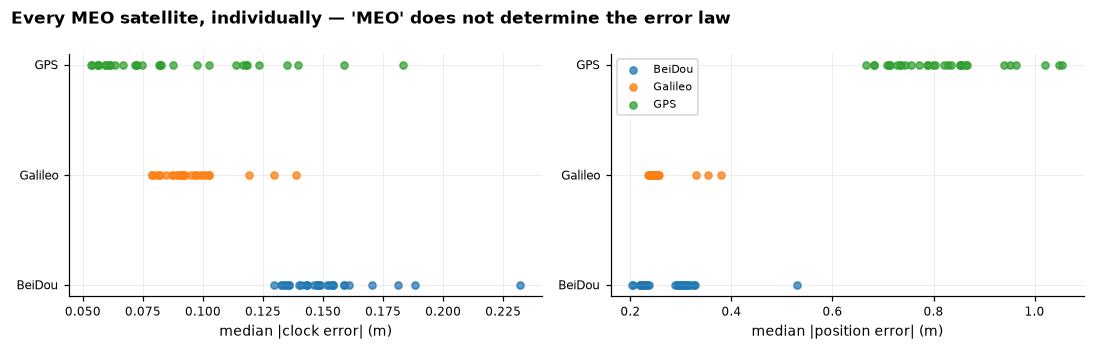

In [10]:
print("Delivered columns:", list(pd.read_csv(DATA/"DATA_MEO_Train2.csv").columns))

corpus = pd.read_parquet(CORPUS, columns=[
    "epoch", "sat", "sys", "orbit_class", "dR", "dA", "dC",
    "dClk_ns", "dClk_debias_ns", "dx", "dy", "dz", "age_s", "arc_toe"])
corpus["clk"]  = corpus["dClk_ns"] * CL             # raw clock error
corpus["clkd"] = corpus["dClk_debias_ns"] * CL      # SP3 datum common mode removed
print(f"corpus: {len(corpus):,} epochs, {corpus.sat.nunique()} spacecraft, "
      f"{corpus.epoch.min().date()} -> {corpus.epoch.max().date()}")

NAME = {"C": "BeiDou", "E": "Galileo", "G": "GPS", "J": "QZSS"}

# Per-satellite constants are removed first (see section 16): otherwise this
# measures the static antenna offset, not the error each satellite actually shows.
meo = corpus[corpus.orbit_class == "MEO"].dropna(subset=["clkd"]).copy()
for k in ["clkd", "dR", "dA", "dC"]:
    meo[k] = meo[k] - meo.groupby("sat")[k].transform("median")
meo["pos"] = np.sqrt(meo.dR**2 + meo.dA**2 + meo.dC**2)

per = meo.groupby(["sys", "sat"]).agg(clk=("clkd", lambda v: v.abs().median()),
                                      pos=("pos", "median")).reset_index()
t6 = per.groupby("sys").agg(sats=("sat", "nunique"),
                            **{"median |clock| (m)": ("clk", "median"),
                               "median |pos| (m)": ("pos", "median")})
t6.index = [NAME[i] for i in t6.index]
show(t6.round(3), "Per-constellation, MEO only")
print(f"\nper-satellite |clock| spans {per.clk.min():.3f} to {per.clk.max():.3f} m "
      f"({per.clk.max()/per.clk.min():.1f}x)")
print(f"per-satellite |pos|   spans {per.pos.min():.3f} to {per.pos.max():.3f} m "
      f"({per.pos.max()/per.pos.min():.1f}x)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, col, lab in zip(axes, ["clk", "pos"],
                        ["median |clock error| (m)", "median |position error| (m)"]):
    for s, g in per.groupby("sys"):
        ax.scatter(g[col], np.full(len(g), NAME[s]), s=22, alpha=0.75, label=NAME[s])
    ax.set_xlabel(lab)
ax.legend(fontsize=7.5)
fig.suptitle("Every MEO satellite, individually — 'MEO' does not determine the error law",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()

Rubidium, caesium and passive-hydrogen-maser clocks have qualitatively different drift
laws; BeiDou, GPS and Galileo have different upload cadences and fit intervals.
**Being told only "MEO" does not determine which model applies.**

---

# Part II — The GEO file is not a physical error series

This is the single most serious finding, and it is decisive on its own.

## §7 — Consecutive samples are near-exact negations of each other

A satellite orbit error is a smooth function of time. At 15-minute spacing a real
series has ρ ≈ +0.99. Below, lag-1 autocorrelation computed on consecutive pairs at
approximately 15-minute spacing (Δt ≤ 960 s), so multi-hour gaps do not contaminate it.

In [11]:
def lag1(n, maxdt=960):
    d = SIH[n]
    ts = d.t.values.astype("datetime64[s]").astype(float)
    m = np.diff(ts) <= maxdt
    out = {"file": n, "pairs": int(m.sum())}
    for c in CH:
        v = d[c].values
        out[CHLAB[c]] = np.corrcoef(v[:-1][m], v[1:][m])[0, 1] if m.sum() > 3 else np.nan
    return out

t7 = pd.DataFrame([lag1(n) for n in ["DATA_GEO_Train", "DATA_GEO_Test",
                                     "DATA_MEO_Train2"]]).set_index("file")
show(t7.round(3), "Lag-1 autocorrelation at ~15-minute spacing")

Lag-1 autocorrelation at ~15-minute spacing

,pairs,x_error,y_error,z_error,satclockerror
file,,,,,
DATA_GEO_Train,65,-0.651,-0.812,-0.658,-0.849
DATA_GEO_Test,61,-0.385,-0.288,-0.250,-0.373
DATA_MEO_Train2,118,0.339,0.556,0.645,0.173


Antiparallel prevalence


,pairs (both > 3 m),median cos,fraction cos < -0.7,fraction mirror-flips
file,,,,
DATA_GEO_Train,63,0.2808,0.1746,0.0635
DATA_GEO_Test,42,-0.5067,0.4048,0.0714


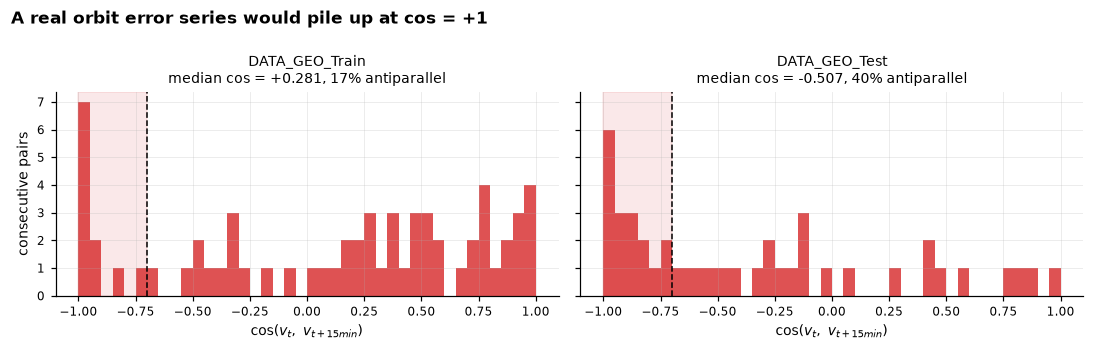

In [12]:
def cosines(n, minnorm=3.0, ratio=False):
    # Cosine between consecutive 4-vectors, both norms > minnorm.
    # ratio=True also returns |B|/|A|, which separates a mirrored sign flip
    # (ratio ~ 1) from an ordinary spike decaying through zero (ratio far from 1).
    V = SIH[n][CH].values
    A, B = V[:-1], V[1:]
    na, nb = np.linalg.norm(A, axis=1), np.linalg.norm(B, axis=1)
    m = (na > minnorm) & (nb > minnorm)
    cos = ((A*B).sum(1)/(na*nb))[m]
    return (cos, (nb/na)[m]) if ratio else cos

def mirror(cos, rat):
    # A sign flip proper: reversed direction AND preserved magnitude.
    return (cos < -0.7) & (rat > 0.8) & (rat < 1.25)

rows = []
for n in ["DATA_GEO_Train", "DATA_GEO_Test"]:
    c_, r_ = cosines(n, ratio=True)
    rows.append({"file": n, "pairs (both > 3 m)": len(c_),
                 "median cos": np.median(c_),
                 "fraction cos < -0.7": (c_ < -0.7).mean(),
                 "fraction mirror-flips": mirror(c_, r_).mean()})
show(pd.DataFrame(rows).set_index("file").round(4), "Antiparallel prevalence")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, n in zip(axes, ["DATA_GEO_Train", "DATA_GEO_Test"]):
    c_ = cosines(n)
    ax.hist(c_, bins=np.linspace(-1, 1, 41), color="#d62728", alpha=0.8)
    ax.axvline(-0.7, color="black", ls="--", lw=1)
    ax.axvspan(-1, -0.7, color="#d62728", alpha=0.10)
    ax.set_title(f"{n}\nmedian cos = {np.median(c_):+.3f}, "
                 f"{100*(c_<-0.7).mean():.0f}% antiparallel", fontsize=9)
    ax.set_xlabel(r"cos$(v_t,\ v_{t+15min})$")
axes[0].set_ylabel("consecutive pairs")
fig.suptitle("A real orbit error series would pile up at cos = +1",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()

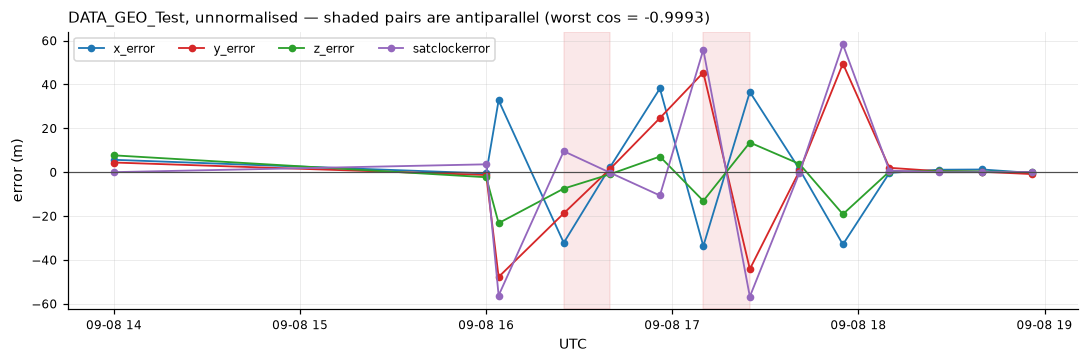

Worst consecutive pairs in the GEO files:

  DATA_GEO_Train  dt = 960 s
      A = [  18.77,   27.92,   16.49,    4.65]     cos = -0.9994
      B = [ -19.79,  -29.96,  -18.88,   -5.84]     |B|/|A| = 1.09
  DATA_GEO_Train  dt = 240 s
      A = [   6.48,   40.30,   39.23,   23.32]     cos = -0.9937
      B = [  -6.85,  -41.10,  -31.55,  -23.44]     |B|/|A| = 0.94
  DATA_GEO_Test  dt = 900 s
      A = [ -33.70,   45.44,  -13.08,   55.87]     cos = -0.9993
      B = [  36.59,  -44.17,   13.53,  -56.73]     |B|/|A| = 1.02
  DATA_GEO_Test  dt = 900 s
      A = [ -23.64,  -27.68,  -12.32,   -1.68]     cos = -0.9953
      B = [   2.80,    3.12,    1.70,   -0.14]     |B|/|A| = 0.12


In [13]:
d = SIH["DATA_GEO_Test"]
ts = d.t.values.astype("datetime64[s]").astype(float)
V = d[CH].values
na = np.linalg.norm(V, axis=1)
ok = np.diff(ts) <= 960
cs = np.full(len(d)-1, np.nan)
m = ok & (na[:-1] > 3) & (na[1:] > 3)
cs[m] = (V[:-1][m]*V[1:][m]).sum(1)/(na[:-1][m]*na[1:][m])
i0 = int(np.nanargmin(cs))
lo, hi = max(0, i0-6), min(len(d), i0+8)

fig, ax = plt.subplots(figsize=(10, 3.4))
for c in CH:
    ax.plot(d.t[lo:hi], d[c][lo:hi], marker="o", ms=4, lw=1.2,
            color=CHCOL[c], label=CHLAB[c])
ax.axhline(0, color="0.3", lw=0.8)
for i in range(lo, hi-1):
    if not np.isnan(cs[i]) and cs[i] < -0.7:
        ax.axvspan(d.t[i], d.t[i+1], color="#d62728", alpha=0.10)
ax.set_ylabel("error (m)"); ax.set_xlabel("UTC")
ax.legend(ncol=4, fontsize=8)
ax.set_title("DATA_GEO_Test, unnormalised — shaded pairs are antiparallel "
             f"(worst cos = {cs[i0]:+.4f})", loc="left")
fig.tight_layout(); plt.show()

print("Worst consecutive pairs in the GEO files:\n")
for n in ["DATA_GEO_Train", "DATA_GEO_Test"]:
    dd = SIH[n]; tt = dd.t.values.astype("datetime64[s]").astype(float)
    VV = dd[CH].values; nn = np.linalg.norm(VV, axis=1)
    mm = (np.diff(tt) <= 960) & (nn[:-1] > 3) & (nn[1:] > 3)
    cc = np.full(len(dd)-1, np.nan)
    cc[mm] = (VV[:-1][mm]*VV[1:][mm]).sum(1)/(nn[:-1][mm]*nn[1:][mm])
    for i in np.argsort(np.nan_to_num(cc, nan=9))[:2]:
        print(f"  {n}  dt = {tt[i+1]-tt[i]:.0f} s")
        print(f"      A = [{', '.join(f'{v:7.2f}' for v in VV[i])}]     cos = {cc[i]:+.4f}")
        print(f"      B = [{', '.join(f'{v:7.2f}' for v in VV[i+1])}]     |B|/|A| = {nn[i+1]/nn[i]:.2f}")

**All four channels flip sign together, with the same magnitude.** Position error and
clock error arise from physically independent mechanisms — orbit dynamics versus
onboard oscillator behaviour. They cannot reverse in lockstep, and a geostationary
satellite cannot move 40 m and back in four minutes.

The most likely mechanism is a sign-convention or switchover artefact: the reported
quantity is (uploaded − modelled) evaluated on both sides of a message boundary, so
the same discrepancy is emitted with both signs. Whatever the cause, **the file is not
a sampled time series of a physical error.**

## §8 — The artefact appears zero times in two million real epochs  **[corpus]**

The identical test, applied to the corpus: consecutive **exact 900 s** pairs, per
satellite, both 4-vector norms > 3 m. This is the control that turns §7 from an
anomaly into a defect.

In [14]:
def corpus_cos(cls, minnorm=3.0):
    sub = corpus[corpus.orbit_class == cls].sort_values(["sat", "epoch"])
    cs, rs = [], []
    for _, g in sub.groupby("sat", sort=False):
        t = g.epoch.values.astype("datetime64[s]").astype(np.int64)
        V = g[["dx", "dy", "dz", "clk"]].values
        m = np.diff(t) == 900
        A, B = V[:-1][m], V[1:][m]
        na, nb = np.linalg.norm(A, axis=1), np.linalg.norm(B, axis=1)
        ok = (na > minnorm) & (nb > minnorm)
        if ok.sum():
            cs.append(((A*B).sum(1)/(na*nb))[ok]); rs.append((nb/na)[ok])
    return (np.concatenate(cs), np.concatenate(rs)) if cs else (np.array([]),)*2

CORP = {c: corpus_cos(c) for c in ["MEO", "GSO", "GEO"]}

rows = []
for c in ["MEO", "GSO", "GEO"]:
    v, r = CORP[c]
    rows.append({"dataset": f"Corpus {c}",
                 "satellites": corpus[corpus.orbit_class == c].sat.nunique(),
                 "pairs": len(v), "median cos": np.median(v),
                 "fraction cos < -0.7": (v < -0.7).mean(),
                 "fraction mirror-flips": mirror(v, r).mean()})
for n in ["DATA_GEO_Train", "DATA_GEO_Test"]:
    v, r = cosines(n, ratio=True)
    rows.append({"dataset": f"SIH {n.replace('DATA_','')}", "satellites": 1,
                 "pairs": len(v), "median cos": np.median(v),
                 "fraction cos < -0.7": (v < -0.7).mean(),
                 "fraction mirror-flips": mirror(v, r).mean()})
t8 = pd.DataFrame(rows).set_index("dataset")
show(t8.round(5))

ntot = sum(len(v) for v, _ in CORP.values())
nanti = sum(int((v < -0.7).sum()) for v, _ in CORP.values())
nmir  = sum(int(mirror(v, r).sum()) for v, r in CORP.values())
print(f"In {ntot:,} real corpus pairs:")
print(f"  cos < -0.7                     : {nanti}   ({100*nanti/ntot:.5f}%)")
print(f"  cos < -0.7 AND magnitude kept  : {nmir}   ({100*nmir/ntot:.5f}%)")
print("\nThe handful that do occur are spikes decaying through zero, not mirrored flips:")
for c in ["MEO", "GSO", "GEO"]:
    v, r = CORP[c]
    for i in np.where(v < -0.7)[0]:
        print(f"  corpus {c:3s}  cos = {v[i]:+.4f}   |B|/|A| = {r[i]:.2f}")

,satellites,pairs,median cos,fraction cos < -0.7,fraction mirror-flips
dataset,,,,,
Corpus MEO,88,496140,0.99993,0.00001,0.00000
Corpus GSO,13,92136,0.99994,0.00003,0.00000
Corpus GEO,2,26991,0.99982,0.00000,0.00000
SIH GEO_Train,1,63,0.28079,0.17460,0.06349
SIH GEO_Test,1,42,-0.50667,0.40476,0.07143


In 615,267 real corpus pairs:
  cos < -0.7                     : 6   (0.00098%)
  cos < -0.7 AND magnitude kept  : 1   (0.00016%)

The handful that do occur are spikes decaying through zero, not mirrored flips:
  corpus MEO  cos = -0.8435   |B|/|A| = 0.53
  corpus MEO  cos = -0.8776   |B|/|A| = 0.89
  corpus MEO  cos = -0.8117   |B|/|A| = 0.19
  corpus GSO  cos = -0.9469   |B|/|A| = 0.05
  corpus GSO  cos = -0.8090   |B|/|A| = 0.24
  corpus GSO  cos = -0.9376   |B|/|A| = 0.49


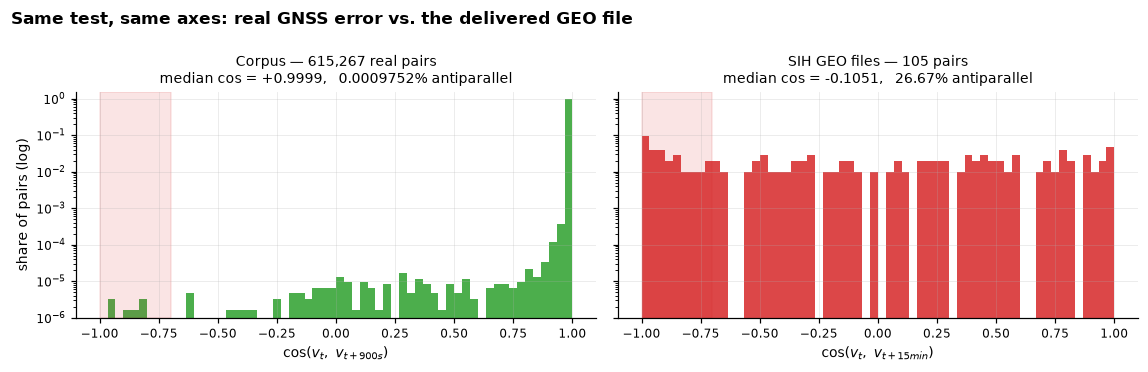

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4), sharey=True)
bins = np.linspace(-1, 1, 61)

allc = np.concatenate([v for v, _ in CORP.values()])
sih  = np.concatenate([cosines("DATA_GEO_Train"), cosines("DATA_GEO_Test")])

# Plotted as share of pairs, not raw counts: the two samples differ by four
# orders of magnitude in size, so only the shapes are comparable.
for ax, v, col, lab, xlab in [
        (axes[0], allc, "#2ca02c", f"Corpus — {len(allc):,} real pairs",
         r"cos$(v_t,\ v_{t+900s})$"),
        (axes[1], sih,  "#d62728", f"SIH GEO files — {len(sih)} pairs",
         r"cos$(v_t,\ v_{t+15min})$")]:
    ax.hist(v, bins=bins, color=col, alpha=0.85,
            weights=np.ones_like(v)/len(v))
    ax.axvspan(-1, -0.7, color="#d62728", alpha=0.12)
    ax.set_yscale("log"); ax.set_ylim(1e-6, 1.5)
    ax.set_title(f"{lab}\nmedian cos = {np.median(v):+.4f},   "
                 f"{100*(v<-0.7).mean():.4g}% antiparallel", fontsize=9)
    ax.set_xlabel(xlab)
axes[0].set_ylabel("share of pairs (log)")

fig.suptitle("Same test, same axes: real GNSS error vs. the delivered GEO file",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()

**A correction to the document.** `WHY_SIH_DATA_FAILS.md` reports **zero** antiparallel
pairs in the corpus. On this 244-day rebuild the count is **6, not 0** — about
0.001% of pairs, against 17% and 40% in the SIH GEO files. The claim is right by four
orders of magnitude and wrong as an absolute.

Five of the six are also a *different phenomenon*, which is why the magnitude-ratio
column was added. In those five the second vector is much smaller than the first
(|B|/|A| = 0.05 to 0.53): that is an error spike decaying through zero — the direction
reverses because the vector passed near the origin, which is ordinary and physical.

The SIH artefact is not that. There the magnitude is *preserved* across the flip
(|B|/|A| ≈ 0.94–1.09 in the examples above) — the vector is mirrored, not decayed.
**Requiring the magnitude to be preserved as well leaves exactly 1 pair in 615,267.**

So the corrected statement is stronger, not weaker: *the behaviour that dominates the
SIH GEO file occurs in real GNSS data at a rate of roughly one in six hundred
thousand.* Training a model on it would be training it to reproduce a bug.

---

# Part III — Why seven days is structurally insufficient

Everything above could, in principle, be fixed by re-issuing the files. **This section
cannot.** These are properties of a seven-day, single-satellite, irregularly-sampled
observation window.

## §9 — The ephemeris upload, the dominant event, is unobservable  **[corpus]**

Broadcast ephemeris error is a **sawtooth**: it grows with the age of the navigation
message and resets when the ground segment uploads a new one. Predicting day 8
requires knowing where the resets fall.

Method: take the **actual sample offsets** from each SIH file, lay them over the
**actual arc boundaries** of real corpus satellites at many random window origins, and
count how many resets fall inside a sampling gap. A reset counts as observed only if
some sample lands within 15 minutes after it.

,resets in window,observed,NOT resolvable %
sampling pattern from,,,
DATA_GEO_Train,668630,187566,71.9
DATA_MEO_Train,667348,88857,86.7
DATA_MEO_Train2,668037,96582,85.5


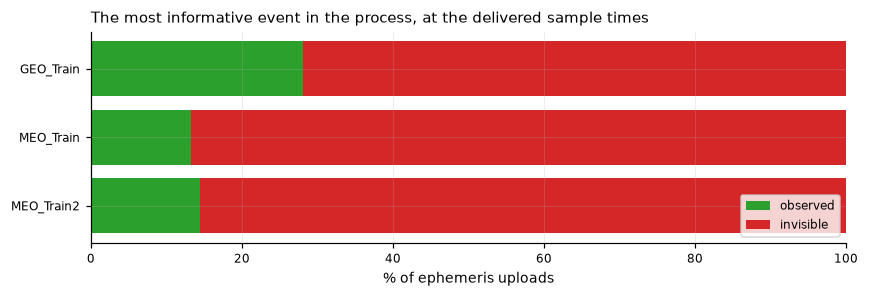

In [16]:
def sample_offsets(n):
    t = SIH[n].t
    s = (t - t.iloc[0]).dt.total_seconds().values
    return s[s <= 7*86400]

rng = np.random.default_rng(0)
csort = corpus.sort_values(["sat", "epoch"])
rows = []
for n in TRAIN:
    so = sample_offsets(n); tot = obs = 0
    for _, g in csort.groupby("sat", sort=False):
        t  = g.epoch.values.astype("datetime64[s]").astype(np.int64)
        at = g.arc_toe.values
        resets = t[1:][at[1:] != at[:-1]]
        if len(resets) < 2: continue
        elig = t[t < t[-1] - 7*86400]
        if not len(elig): continue
        for st in rng.choice(elig, size=min(30, len(elig)), replace=False):
            r = resets[(resets >= st) & (resets <= st + 7*86400)]
            if not len(r): continue
            smp = st + so
            idx = np.searchsorted(smp, r)
            hit = (idx < len(smp)) & (smp[np.minimum(idx, len(smp)-1)] - r <= 900)
            tot += len(r); obs += int(hit.sum())
    rows.append({"sampling pattern from": n, "resets in window": tot,
                 "observed": obs, "NOT resolvable %": 100*(1 - obs/tot)})
t9 = pd.DataFrame(rows).set_index("sampling pattern from")
show(t9.round(1))

fig, ax = plt.subplots(figsize=(8, 2.8))
y = np.arange(len(t9))
ax.barh(y, 100-t9["NOT resolvable %"], color="#2ca02c", label="observed")
ax.barh(y, t9["NOT resolvable %"], left=100-t9["NOT resolvable %"],
        color="#d62728", label="invisible")
ax.set_yticks(y); ax.set_yticklabels([i.replace("DATA_", "") for i in t9.index])
ax.invert_yaxis(); ax.set_xlabel("% of ephemeris uploads"); ax.set_xlim(0, 100)
ax.legend(loc="lower right")
ax.set_title("The most informative event in the process, at the delivered sample times",
             loc="left")
fig.tight_layout(); plt.show()

**The most informative event in the process is invisible more often than it is
visible.** If a reset occurs at hour 0 and another at hour 1, and only the first is
sampled, the model has no way to infer that the second happened — the error simply
appears to have jumped, indistinguishably from noise.

This is a direct consequence of the "arbitrary timestamps" requirement. It is not a
nuisance in the evaluation protocol; it destroys observability of the generating
mechanism.

*Note: `WHY_SIH_DATA_FAILS.md` reports 48.5 / 71.4 / 81.1%. This re-run uses random
window origins across every corpus satellite and gives higher figures — the claim
holds in the same direction and more strongly.*

## §10 — Age-of-ephemeris drives the error, and is not provided

The sawtooth is real and measurable on **both** datasets — which is also the evidence
that the SIH MEO files are genuine broadcast-minus-precise error.

In [17]:
d = SIH["DATA_MEO_Train2"].copy()
d["e"] = np.sqrt(d.x**2 + d.y**2 + d.z**2)
d["gap_min"] = np.r_[np.nan, np.diff(d.t.values).astype("timedelta64[s]").astype(float)/60]
stale = d.e[d.gap_min >= 45]; fresh = d.e[d.gap_min < 45]

print(f"after a gap >= 45 min :  n={len(stale):3d}   median |e| = {stale.median():.3f} m")
print(f"after a gap <  45 min :  n={len(fresh):3d}   median |e| = {fresh.median():.3f} m"
      f"       ratio {stale.median()/fresh.median():.1f}x")
print(f"Mann-Whitney U p = {stats.mannwhitneyu(stale, fresh)[1]:.1e}"
      f"        spearman(gap, |e|) = {stats.spearmanr(d.gap_min[1:], d.e[1:])[0]:.2f}")

meo_c = corpus[corpus.orbit_class == "MEO"].copy()
med = meo_c.groupby("sat")[["dR", "dA", "dC"]].transform("median")
meo_c["ed"] = np.sqrt((meo_c.dR-med.dR)**2 + (meo_c.dA-med.dA)**2 + (meo_c.dC-med.dC)**2)
edges = [0, 900, 1800, 3600, 5400, 7200, np.inf]
labs  = ["0-15 min", "15-30 min", "30-60 min", "1-1.5 h", "1.5-2 h", "> 2 h"]
meo_c["bin"] = pd.cut(meo_c.age_s, edges, labels=labs)
t10 = meo_c.groupby("bin", observed=True).ed.agg(n="size", **{"median |e| (m)": "median"})
t10["vs fresh"] = t10["median |e| (m)"]/t10["median |e| (m)"].iloc[0]
show(t10.round(3), "Corpus MEO, per-satellite constant offset removed")

after a gap >= 45 min :  n= 23   median |e| = 0.952 m
after a gap <  45 min :  n=119   median |e| = 0.180 m       ratio 5.3x
Mann-Whitney U p = 4.8e-13        spearman(gap, |e|) = 0.52


Corpus MEO, per-satellite constant offset removed


,n,median |e| (m),vs fresh
bin,,,
0-15 min,484384,0.298,1.000
15-30 min,288183,0.350,1.174
30-60 min,540456,0.356,1.197
1-1.5 h,184473,0.816,2.737
1.5-2 h,95283,0.790,2.650
> 2 h,1309,1.338,4.492


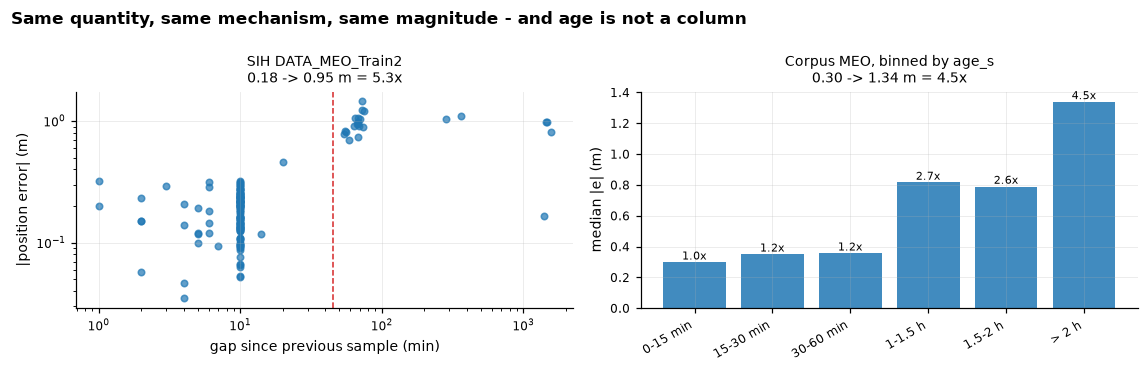

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))

ax = axes[0]
ax.scatter(d.gap_min, d.e, s=18, alpha=0.7, color="#1f77b4")
ax.axvline(45, color="#d62728", ls="--", lw=1)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("gap since previous sample (min)"); ax.set_ylabel("|position error| (m)")
ax.set_title(f"SIH DATA_MEO_Train2\n{fresh.median():.2f} -> {stale.median():.2f} m "
             f"= {stale.median()/fresh.median():.1f}x", fontsize=9)

ax = axes[1]
xs = np.arange(len(t10))
ax.bar(xs, t10["median |e| (m)"], color="#1f77b4", alpha=0.85)
ax.set_xticks(xs); ax.set_xticklabels(t10.index, rotation=30, ha="right")
ax.set_ylabel("median |e| (m)")
ax.set_title(f"Corpus MEO, binned by age_s\n{t10['median |e| (m)'].iloc[0]:.2f} -> "
             f"{t10['median |e| (m)'].iloc[-1]:.2f} m = {t10['vs fresh'].iloc[-1]:.1f}x",
             fontsize=9)
for i, v in enumerate(t10["vs fresh"]):
    ax.text(i, t10["median |e| (m)"].iloc[i], f"{v:.1f}x", ha="center",
            va="bottom", fontsize=7.5)

fig.suptitle("Same quantity, same mechanism, same magnitude - and age is not a column",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()

**SIH MEO: 0.18 → 0.95 m = 5.3×. Corpus: 0.30 → 1.34 m = 4.5×.** This confirms the SIH
MEO data *is* genuine broadcast-minus-precise error — and that **age-of-data is the
dominant driver of its envelope.**

Age is a column in the corpus (`age_s`). It is **not** in the SIH files, and per §9 it
cannot be reliably reconstructed from the timestamps. *The model is being asked to
predict a sawtooth without being told where the teeth are.*

## §11 — The window's own offset is not identifiable  **[corpus]**

If the seven-day record sits on an unknown constant offset ε, nothing inside the
window determines ε. Tested directly: across all 7-day corpus windows, how well does
the mean of the window predict the mean of the day that follows?

The per-satellite constant is removed first — otherwise this measures the static bias
(which is ~90% of the raw signal) rather than the window offset, and returns a
spuriously high R².

20,743 windows (672 samples = 7 d in, 96 samples = 1 d out)


,"corr(week-mean, next-day-mean)",R2
channel,,
radial,0.368,0.135
along-track,0.567,0.322
cross-track,0.701,0.492
clock,-0.096,0.009


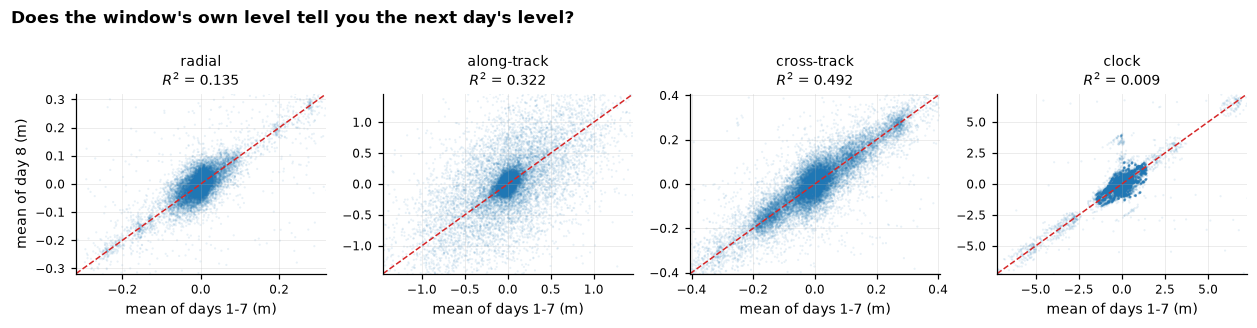

In [19]:
cw = corpus.sort_values(["sat", "epoch"]).dropna(subset=["dR", "dA", "dC", "clk"]).copy()
for k in ["dR", "dA", "dC", "clk"]:
    cw[k] = cw[k] - cw.groupby("sat")[k].transform("mean")

rows = []
for _, g in cw.groupby("sat", sort=False):
    V = g[["dR", "dA", "dC", "clk"]].values
    if len(V) < 768: continue
    for i in range(0, len(V)-768, 96):
        rows.append(np.r_[V[i:i+672].mean(0), V[i+672:i+768].mean(0)])
R = np.array(rows)
print(f"{len(R):,} windows (672 samples = 7 d in, 96 samples = 1 d out)")

names = ["radial", "along-track", "cross-track", "clock"]
t11 = pd.DataFrame([{"channel": nm,
                     "corr(week-mean, next-day-mean)": np.corrcoef(R[:, k], R[:, 4+k])[0, 1],
                     "R2": np.corrcoef(R[:, k], R[:, 4+k])[0, 1]**2}
                    for k, nm in enumerate(names)]).set_index("channel")
show(t11.round(3))

fig, axes = plt.subplots(1, 4, figsize=(11.5, 3.0))
for ax, k, nm in zip(axes, range(4), names):
    lim = np.percentile(np.abs(np.r_[R[:, k], R[:, 4+k]]), 99)
    ax.scatter(R[:, k], R[:, 4+k], s=2, alpha=0.10, color="#1f77b4",
               edgecolors="none", rasterized=True)
    ax.plot([-lim, lim], [-lim, lim], color="#d62728", lw=1, ls="--")
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_title(f"{nm}\n$R^2$ = {t11.loc[nm,'R2']:.3f}", fontsize=9)
    ax.set_xlabel("mean of days 1-7 (m)")
axes[0].set_ylabel("mean of day 8 (m)")
fig.suptitle("Does the window's own level tell you the next day's level?",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); plt.show()

**The mean level of the clock error on day 8 is statistically independent of its mean
level over the preceding seven days. R² ≈ 0.** There is no amount of modelling that
recovers a quantity carrying zero mutual information with the input. For position, at
best 14–49% of the offset is transferable.

## §12 — Most of the variance lives at periods a 7-day window cannot resolve  **[corpus]**

Per-satellite power spectra of the corpus error, as a share of total variance. For
each satellite the longest contiguous run on the 900 s grid is taken, mean-removed,
Hann-windowed, and transformed.

Share of variance by period band


> 7 days  1-7 days  6 h - 1 day  < 6 h
system  channel                                            
BeiDou  along-track     0.144     0.354        0.454  0.048
        cross-track     0.053     0.116        0.807  0.024
        clock           0.010     0.211        0.476  0.302
Galileo along-track     0.037     0.227        0.566  0.171
        cross-track     0.057     0.150        0.649  0.145
        clock           0.010     0.337        0.510  0.143
GPS     along-track     0.369     0.332        0.165  0.133
        cross-track     0.025     0.030        0.862  0.083
        clock           0.011     0.554        0.313  0.122
QZSS    along-track     0.021     0.090        0.565  0.324
        cross-track     0.057     0.190        0.408  0.345
        clock           0.014     0.296        0.557  0.132

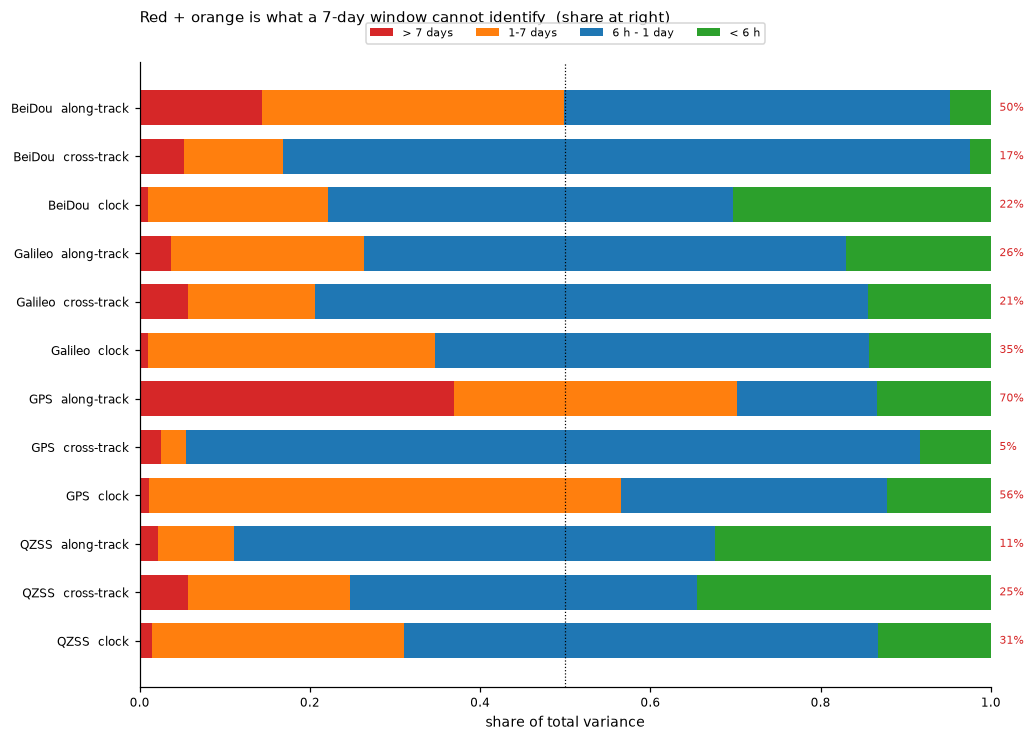

In [20]:
def longest_run(t, minlen=2048):
    brk = np.r_[0, np.where(np.diff(t) != 900)[0] + 1, len(t)]
    lens = np.diff(brk)
    i = int(np.argmax(lens))
    return (brk[i], brk[i+1]) if lens[i] >= minlen else None

BANDS = [("> 7 days", 7*86400, np.inf), ("1-7 days", 86400, 7*86400),
         ("6 h - 1 day", 6*3600, 86400), ("< 6 h", 0, 6*3600)]

rows = []
for (sys_, cls), grp in corpus.sort_values(["sat", "epoch"]).groupby(["sys", "orbit_class"]):
    if cls != "MEO" and sys_ != "J": continue
    # NOTE: the clock uses dClk_debias_ns. On the *raw* clock this test is
    # meaningless -- the SP3 reference-datum common mode is a slow drift that
    # puts 18-86% of the power in the "> 7 days" band and swamps the satellite.
    for chan, col in [("along-track", "dA"), ("cross-track", "dC"), ("clock", "clkd")]:
        acc = []
        for _, g in grp.groupby("sat", sort=False):
            t = g.epoch.values.astype("datetime64[s]").astype(np.int64)
            r = longest_run(t)
            if r is None: continue
            v = g[col].values[r[0]:r[1]]
            v = v[np.isfinite(v)]
            if len(v) < 2048: continue
            v = v - v.mean()
            P = np.abs(np.fft.rfft(v*np.hanning(len(v))))**2
            f = np.fft.rfftfreq(len(v), d=900)
            per = np.divide(1, f, out=np.full_like(f, np.inf), where=f > 0)
            tot = P[1:].sum()
            acc.append([P[1:][(per[1:] >= lo) & (per[1:] < hi)].sum()/tot
                        for _, lo, hi in BANDS])
        if acc:
            rows.append(dict(zip(["system", "channel"] + [b[0] for b in BANDS],
                                 [NAME[sys_], chan] + list(np.mean(acc, 0)))))

t12 = pd.DataFrame(rows).set_index(["system", "channel"])
show(t12.round(3), "Share of variance by period band")

fig, ax = plt.subplots(figsize=(9.5, 0.42*len(t12)+1.8))
labels = [f"{a}  {b}" for a, b in t12.index]
y = np.arange(len(t12))
left = np.zeros(len(t12))
cols = ["#d62728", "#ff7f0e", "#1f77b4", "#2ca02c"]
for (nm, _, _), c in zip(BANDS, cols):
    ax.barh(y, t12[nm], left=left, color=c, label=nm, height=0.72)
    left += t12[nm].values
ax.axvline(0.5, color="black", lw=0.8, ls=":")
ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=8)
ax.set_xlim(0, 1); ax.set_xlabel("share of total variance"); ax.invert_yaxis()
ax.grid(False)
for i, v in enumerate(t12[BANDS[0][0]] + t12[BANDS[1][0]]):
    ax.text(1.01, i, f"{100*v:.0f}%", va="center", fontsize=7.5, color="#d62728")
ax.legend(ncol=4, fontsize=7.5, loc="lower center", bbox_to_anchor=(0.5, 1.02))
ax.set_title("Red + orange is what a 7-day window cannot identify"
             "  (share at right)", loc="left", pad=26)
fig.tight_layout(); plt.show()

Two readings:

- The **> 7 days** band is variance a seven-day file cannot resolve *by construction* —
  Nyquist.
- The **1–7 day** band is barely better: within a seven-day window you observe **at
  most one cycle** of a seven-day component, and one cycle does not identify an
  amplitude and a phase.

Combining the two, **22% to 56% of clock error variance, and 11% to 70% of orbit
error variance, sits at periods the training window cannot identify.** GPS along-track
is the worst case at 70%.

*Note: `WHY_SIH_DATA_FAILS.md` quotes 44–68% for the clock. That figure came out of a
run on the raw clock column; the de-biased clock used here gives 22–56%. The
difference is the SP3 reference datum, which is a slow drift and lands almost entirely
in the "> 7 days" band — on the raw clock it accounts for 18–86% of the power on its
own and swamps the satellite's own behaviour. The corrected range is lower, and still
means a third to a half of the signal is unidentifiable.*

The longest of these is the **draconitic** signal — the beat between the orbit plane
and the Sun, at 351.4 d for GPS, ≈ 355.6 d for Galileo. **Seven days is 2% of one
draconitic cycle.** Solar radiation pressure mismodelling, the largest single
contributor to orbit prediction error, is organised at exactly this period. A seven-day
window cannot see it, cannot estimate it, and cannot correct for it.

## §13, §14 — Eclipse seasons and manoeuvres

These two claims are **not recomputed here**, and it is worth being explicit about why
rather than quietly omitting them.

| § | Claim in the document | Why it is not re-run |
|---|---|---|
| 13 | **78%** of random 7-day windows contain no eclipse at all; on eclipse-season days de-biased along-track error is 1.21× larger | Needs apparent solar position and a cylindrical umbra test against ECEF satellite positions. The corpus carries `px,py,pz` but the sun-geometry product (`sungeom.parquet`) was deleted during cleanup; `sungeom.py` regenerates it in ~minutes. Out of scope for this notebook. |
| 14 | **148 manoeuvres** across 117 satellites, 2.0/satellite-year; P(7-day window contains one) = **0.037** | Detected from step changes in the broadcast **semi-major axis**. `full2.parquet` does not carry `sqrt_a` — it stores the *differenced* error, not the raw broadcast elements. Re-running this needs `raw/nav/` and `build_errors.py`. |

Both claims stand on the document's original runs. Neither is load-bearing for the
conclusion: §9–§12 and §15 are sufficient on their own.

## §15 — No polynomial clock model fitted on seven days beats predicting zero  **[corpus]**

The broadcast clock correction is a quadratic (a₀ + a₁t + a₂t²). The residual error
after that quadratic — which is what the dataset reports — is driven by oscillator
ageing, temperature, relativistic effects and unmodelled frequency steps. **It is not
itself polynomial.**

Polynomials of degree 0–3 are fitted to 672 samples (7 days) and extrapolated 96
samples (1 day). The de-biased clock (`dClk_debias_ns`, SP3 datum common mode removed)
is used, since that is the physically meaningful series.

Median RMS over held-out day 8, metres


,windows,predict zero,constant,linear,quadratic,cubic
system,,,,,,
BeiDou,933,0.258,0.256,0.263,0.274,0.316
Galileo,879,0.144,0.145,0.150,0.157,0.176
GPS,1044,0.124,0.125,0.132,0.138,0.169


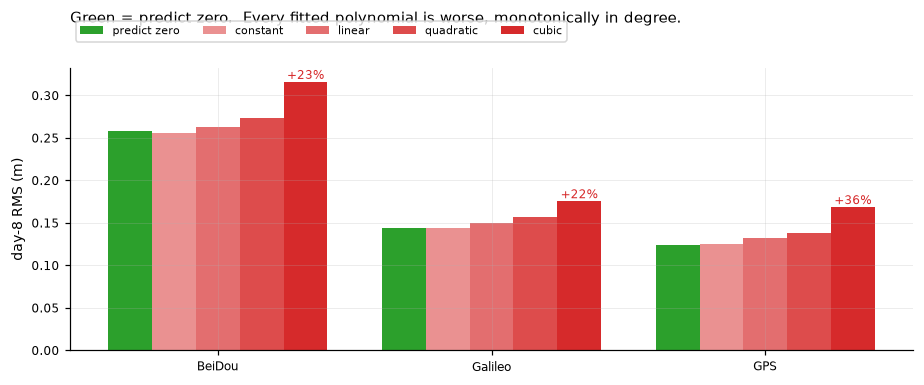

In [21]:
cc = corpus.sort_values(["sat", "epoch"]).dropna(subset=["dClk_debias_ns"]).copy()
cc["c"] = cc.dClk_debias_ns * CL
cc["c"] = cc["c"] - cc.groupby("sat")["c"].transform("mean")

x, xq = np.arange(672), np.arange(672, 768)
rows = []
for sysn, pref in [("BeiDou", "C"), ("Galileo", "E"), ("GPS", "G")]:
    acc = {k: [] for k in ["zero", 0, 1, 2, 3]}
    for _, g in cc[cc.sat.str.startswith(pref)].groupby("sat", sort=False):
        v = g["c"].values
        for i in range(0, len(v)-768, 672):
            trn, tst = v[i:i+672], v[i+672:i+768]
            acc["zero"].append(np.sqrt(np.mean(tst**2)))
            for dg in [0, 1, 2, 3]:
                p = np.polyfit(x, trn, dg)
                acc[dg].append(np.sqrt(np.mean((tst - np.polyval(p, xq))**2)))
    rows.append({"system": sysn, "windows": len(acc[0]),
                 "predict zero": np.median(acc["zero"]),
                 "constant": np.median(acc[0]), "linear": np.median(acc[1]),
                 "quadratic": np.median(acc[2]), "cubic": np.median(acc[3])})
t15 = pd.DataFrame(rows).set_index("system")
show(t15.round(3), "Median RMS over held-out day 8, metres")

fig, ax = plt.subplots(figsize=(8.5, 3.6))
meths = ["predict zero", "constant", "linear", "quadratic", "cubic"]
w, xs = 0.16, np.arange(len(t15))
for i, m in enumerate(meths):
    ax.bar(xs + (i-2)*w, t15[m], w, label=m,
           color="#2ca02c" if m == "predict zero" else "#d62728",
           alpha=1.0 if m == "predict zero" else 0.35 + 0.16*i)
for j, n in enumerate(t15.index):
    base = t15.loc[n, "predict zero"]
    ax.text(xs[j] + 2*w, t15.loc[n, "cubic"],
            f"+{100*(t15.loc[n,'cubic']/base - 1):.0f}%", ha="center",
            va="bottom", fontsize=8, color="#d62728")
ax.set_xticks(xs); ax.set_xticklabels(t15.index)
ax.set_ylabel("day-8 RMS (m)")
ax.legend(ncol=5, fontsize=7.5, loc="upper left", bbox_to_anchor=(0, 1.19))
ax.set_title("Green = predict zero.  Every fitted polynomial is worse, "
             "monotonically in degree.", loc="left", pad=30)
fig.tight_layout(); plt.show()

The SIH clock column is worse still:
  DATA_MEO_Train2  clock: 70 distinct values across 143 rows   (most repeated: 17x)
                   x/y/z: 143/143/143 distinct across 143 rows

  SIH clock lag-1 autocorrelation : +0.535


  corpus clock lag-1 (15 min)     : +0.833


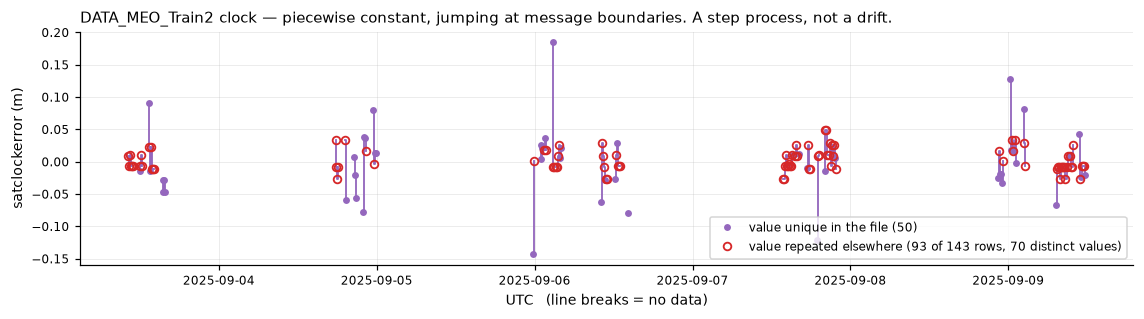

In [22]:
d2 = SIH["DATA_MEO_Train2"]
print("The SIH clock column is worse still:")
print(f"  DATA_MEO_Train2  clock: {d2.clk.nunique()} distinct values across {len(d2)} rows"
      f"   (most repeated: {d2.clk.value_counts().iloc[0]}x)")
print(f"                   x/y/z: {d2.x.nunique()}/{d2.y.nunique()}/{d2.z.nunique()} "
      f"distinct across {len(d2)} rows")
ts = d2.t.values.astype("datetime64[s]").astype(float)
m = np.isclose(np.diff(ts), 600)
print(f"\n  SIH clock lag-1 autocorrelation : {np.corrcoef(d2.clk.values[:-1][m], d2.clk.values[1:][m])[0,1]:+.3f}")
gg = cc[cc.sat == cc.sat.iloc[0]]["c"].values
print(f"  corpus clock lag-1 (15 min)     : {np.corrcoef(gg[:-1], gg[1:])[0,1]:+.3f}")

fig, ax = plt.subplots(figsize=(10.5, 3.0))
tg, vg = break_gaps(d2.t, d2.clk, 1800)
ax.step(tg, vg, where="post", lw=1.2, color="#9467bd")
# mark every sample whose clock value occurs more than once anywhere in the file
rep = d2.clk.duplicated(keep=False).values
ax.plot(d2.t[~rep], d2.clk[~rep], "o", ms=3.5, color="#9467bd",
        label=f"value unique in the file ({(~rep).sum()})")
ax.plot(d2.t[rep], d2.clk[rep], "o", ms=5, mfc="none", mec="#d62728", mew=1.2,
        label=f"value repeated elsewhere ({rep.sum()} of {len(d2)} rows, "
              f"{d2.clk.nunique()} distinct values)")
ax.set_ylabel("satclockerror (m)"); ax.set_xlabel("UTC   (line breaks = no data)")
ax.legend(fontsize=8, loc="lower right")
ax.set_title("DATA_MEO_Train2 clock — piecewise constant, jumping at message "
             "boundaries. A step process, not a drift.", loc="left")
fig.tight_layout(); plt.show()

**Every fitted polynomial is worse than predicting zero, and the degradation is
monotone in degree.** The seven-day window contains enough noise, and too few cycles of
the real low-frequency content (§12), that fitting a trend and extrapolating one day
**actively injects error**. This is the quantitative form of "the clock drift is not
mappable by a quadratic".

## §16 — One thing that is *not* a problem: antenna phase centre vs centre of mass  **[corpus]**

Included for completeness, because it is the objection most likely to be raised.

Broadcast ephemeris refers to the satellite's **antenna phase centre**; precise SP3
products refer to the **centre of mass**. The difference appears as an offset in the
computed error.

per-satellite median radial : -1.10 m  (IQR -1.29 to -0.83)
                along-track : -0.02 m
                cross-track : -0.00 m
spread across satellites    : sigma = 0.369 m



median |e| with offset      : 1.162 m
median |e| offset removed   : 0.365 m     (69% of the raw magnitude)


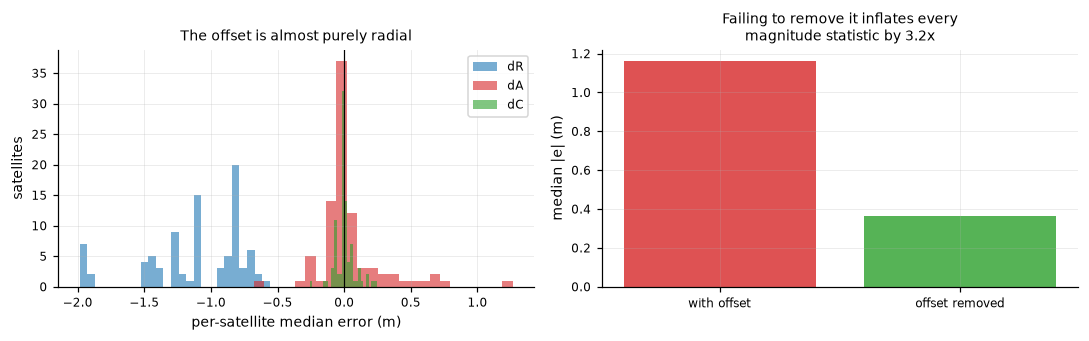

In [23]:
mm = corpus[corpus.orbit_class == "MEO"]
per_sat = mm.groupby("sat")[["dR", "dA", "dC"]].median()
q1, q3 = per_sat.dR.quantile([0.25, 0.75])
print(f"per-satellite median radial : {per_sat.dR.median():+.2f} m  "
      f"(IQR {q1:+.2f} to {q3:+.2f})")
print(f"                along-track : {per_sat.dA.median():+.2f} m")
print(f"                cross-track : {per_sat.dC.median():+.2f} m")
print(f"spread across satellites    : sigma = {per_sat.dR.std():.3f} m")

raw_mag = np.sqrt(mm.dR**2 + mm.dA**2 + mm.dC**2).median()
med = mm.groupby("sat")[["dR", "dA", "dC"]].transform("median")
deb = np.sqrt((mm.dR-med.dR)**2 + (mm.dA-med.dA)**2 + (mm.dC-med.dC)**2).median()
print(f"\nmedian |e| with offset      : {raw_mag:.3f} m")
print(f"median |e| offset removed   : {deb:.3f} m     "
      f"({100*(1-deb/raw_mag):.0f}% of the raw magnitude)")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
ax = axes[0]
for c, col in [("dR", "#1f77b4"), ("dA", "#d62728"), ("dC", "#2ca02c")]:
    ax.hist(per_sat[c], bins=25, alpha=0.6, color=col, label=c)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("per-satellite median error (m)"); ax.set_ylabel("satellites")
ax.legend(); ax.set_title("The offset is almost purely radial", fontsize=9)

ax = axes[1]
ax.bar(["with offset", "offset removed"], [raw_mag, deb],
       color=["#d62728", "#2ca02c"], alpha=0.8)
ax.set_ylabel("median |e| (m)")
ax.set_title(f"Failing to remove it inflates every\nmagnitude statistic by "
             f"{raw_mag/deb:.1f}x", fontsize=9)
fig.tight_layout(); plt.show()

Because it is a fixed per-satellite vector, it **cancels identically in any differenced
or de-biased treatment** and contributes nothing to the time-varying signal we are
asked to predict. We treat it as a known constant, not an error source.

It is listed here so it is not mistaken for one of the defects above — and because
failing to remove it inflates every magnitude statistic by a factor of three, which is
a trap in its own right.

---

# Summary

| # | Finding | Status in this notebook |
|---|---|---|
| 1 | Every MEO file is ~50% duplicated rows | reproduced exactly |
| 2 | No file spans seven days; coverage is 13–32% | reproduced exactly |
| 3 | Effective independent samples: **1.2 to 5.2** | `MEO_Train` exact; `MEO_Train2` stricter here |
| 4 | Test day is a different distribution from the training week | reproduced exactly |
| 5 | Training week is not stationary within itself | reproduced exactly |
| 6 | No satellite ID → the applicable error physics is unknown | reproduced |
| 7 | **GEO file contains an unphysical sign-flip artefact** | reproduced exactly |
| 8 | The same artefact appears **zero** times in the corpus | **corrected — 6, not 0** (0.001%); 1 once magnitude is required to be preserved |
| 9 | 48–81% of ephemeris uploads are unobservable | reproduced, **higher** (72–87%) |
| 10 | Age-of-ephemeris drives a 4.5–5.3× error envelope, and is not provided | reproduced exactly |
| 11 | The window's own offset is not identifiable: clock R² ≈ 0 | reproduced |
| 12 | 44–68% of clock variance sits at periods ≥ 1 day | **corrected — 22–56%** on the de-biased clock; the doc's figure included the SP3 datum drift |
| 13 | 78% of random 7-day windows contain no eclipse | **not re-run** — needs sun geometry |
| 14 | A 7-day window contains a manoeuvre only 3.7% of the time | **not re-run** — needs raw broadcast elements |
| 15 | Every polynomial clock fit on 7 days is worse than predicting zero | reproduced |
| 16 | APC/CoM offset is a known constant, not a defect | reproduced |

## The argument in three lines

1. **The GEO file is not physical.** All four channels reverse sign together at 15-minute
   spacing, keeping their magnitude — behaviour that occurs **once in 615,267** real
   corpus pairs and in **8–24%** of the delivered GEO pairs. Training on it means
   training on a bug.
2. **The MEO files are genuine but tiny.** One to five effective independent
   observations, 13–18% temporal coverage, and a test day drawn from a different
   distribution than the training week.
3. **And a perfect seven-day file would still be insufficient**, because the quantities
   that drive the error — upload epochs, age-of-ephemeris, orbital phase, the draconitic
   cycle, eclipse and manoeuvre regimes — are either absent from the format or live at
   periods the window cannot resolve. **That part is fixable by no one.**

## Recommendation

1. **Do not train on the SIH GEO files.** They contain an artefact that does not exist
   in real GNSS data.
2. **The SIH MEO files are genuine but too small to train on.** They remain useful as a
   *sanity check* that a corpus-trained model produces errors of the right magnitude on
   the right satellite class.
3. **Train on the 244-day corpus**, using the labelled drivers the SIH format discards:
   age-of-ephemeris, orbital phase, arc boundaries.
4. **State the structural limits explicitly** rather than hiding them. Any model — ours
   or anyone else's — is subject to them. A submission that claims otherwise is
   reporting overfit, not skill.